In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

file_path= r"C:\Data Analyst\End to End Projects\python+sql+powerbi+excel\AB Test Checkout\Data\AB_Data.csv"
df=pd.read_csv(file_path)

# Display first 5 rows:
print(df.head())

# Check Total rows and columns
print("Dataset Shape: ", df.shape)

# Check Columns
print("\n Column Names: ", df.columns.tolist())

# Check dataset Info:
print("\n Check Dataset Info:  ")
df.info()

   user_id    variant  converted
0        1  Treatment          0
1        2    Control          0
2        3  Treatment          0
3        4  Treatment          0
4        5  Treatment          0
Dataset Shape:  (12000, 3)

 Column Names:  ['user_id', 'variant', 'converted']

 Check Dataset Info:  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   user_id    12000 non-null  int64 
 1   variant    12000 non-null  object
 2   converted  12000 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 281.4+ KB


In [12]:
# Check Missing Values
print("\n Missing Value: ")
print(df.isnull().sum())

print("\n Total Missing Values: ", df.isnull().sum().sum())

# Count exact duplicate rows
print("\n Exact Duplicate Rows:", df.duplicated().sum())

# Check duplicate user IDs
print("\n Duplicate User IDs:", df["user_id"].duplicated().sum())


 Missing Value: 
user_id      0
variant      0
converted    0
dtype: int64

 Total Missing Values:  0

 Exact Duplicate Rows: 0

 Duplicate User IDs: 0


In [13]:
# Identify Exp Groups
print("\n Expirement Groups: ")
print(df["variant"].unique())

# count users in each exp group
print("\n Users in each group: ")
print(df["variant"].value_counts())


 Expirement Groups: 
['Treatment' 'Control']

 Users in each group: 
variant
Treatment    6009
Control      5991
Name: count, dtype: int64


In [14]:
# Count conversion outcomes
print("Conversion Outcomes:")
print(df["converted"].value_counts())

Conversion Outcomes:
converted
0    10534
1     1466
Name: count, dtype: int64


In [15]:
# Hypothesis Formulation

# Null Hypothesis (H0):
# Control and Treatment have equal true conversion rates.

# Alternative Hypothesis (H1):
# Control and Treatment have different true conversion rates.

# Significance level
alpha=0.05

print("Null Hypothesis (HO): p_T= p_C")
print("Alternative Hypothesis (H1): p_T != p_C ")
print("Significance Level: ", alpha)

Null Hypothesis (HO): p_T= p_C
Alternative Hypothesis (H1): p_T != p_C 
Significance Level:  0.05


In [16]:
from statsmodels.stats.proportion import proportions_ztest

# Number of converted users
count = np.array([791, 675])

# Total users in each group
nobs = np.array([6009, 5991])

# Perform two-proportion z-test
z_stat, p_value = proportions_ztest(
    count,
    nobs,
    alternative="two-sided"
)

print("Z-Statistic:", z_stat)
print("P-Value:", p_value)

# Interpret the results
alpha = 0.05

if p_value < alpha:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Z-Statistic: 3.1722948617892204
P-Value: 0.0015123936489494984
Reject Null Hypothesis


In [17]:
from statsmodels.stats.proportion import confint_proportions_2indep

# Calculate group-wise users and conversions
group_summary = df.groupby("variant").agg(
    total_users=("converted", "size"),
    converted_users=("converted", "sum")
)

# Extract Treatment values
treatment_users = group_summary.loc["Treatment", "total_users"]
treatment_converted = group_summary.loc["Treatment", "converted_users"]

# Extract Control values
control_users = group_summary.loc["Control", "total_users"]
control_converted = group_summary.loc["Control", "converted_users"]

# Calculate 95% Confidence Interval
ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_converted,
    nobs1=treatment_users,
    count2=control_converted,
    nobs2=control_users,
    method="wald",
    compare="diff",
    alpha=0.05
)

# Convert into percentage points
ci_low = ci_low * 100
ci_high = ci_high * 100

print("95% Confidence Interval")
print("Lower Bound:", round(ci_low, 4))
print("Upper Bound:", round(ci_high, 4))

95% Confidence Interval
Lower Bound: 0.7255
Upper Bound: 3.0679


In [18]:
from statsmodels.stats.proportion import confint_proportions_2indep

# Calculate group-wise users and conversions
group_summary = df.groupby("variant").agg(
    total_users=("converted", "size"),
    converted_users=("converted", "sum")
)

# Extract Treatment values
treatment_users = group_summary.loc["Treatment", "total_users"]
treatment_converted = group_summary.loc["Treatment", "converted_users"]

# Extract Control values
control_users = group_summary.loc["Control", "total_users"]
control_converted = group_summary.loc["Control", "converted_users"]

# Calculate 95% Confidence Interval
ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_converted,
    nobs1=treatment_users,
    count2=control_converted,
    nobs2=control_users,
    method="wald",
    compare="diff",
    alpha=0.05
)

# Convert into percentage points
ci_low = ci_low * 100
ci_high = ci_high * 100

print("95% Confidence Interval")
print("Lower Bound:", round(ci_low, 4))
print("Upper Bound:", round(ci_high, 4))

95% Confidence Interval
Lower Bound: 0.7255
Upper Bound: 3.0679


In [19]:
from scipy.stats import chisquare

# Actual group allocation
observed = np.array([control_users, treatment_users])

# Expected group allocation (50:50)
total_users = observed.sum()
expected = np.array([total_users / 2, total_users / 2])

# Perform Chi-Square Goodness-of-Fit Test
chi_stat, srm_p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

# Display results
print("SRM Check Results")
print("-----------------")
print("Chi-Square Statistic:", round(chi_stat, 4))
print("SRM P-Value:", round(srm_p_value, 6))

SRM Check Results
-----------------
Chi-Square Statistic: 0.027
SRM P-Value: 0.869482


In [20]:
# Set decision thresholds
alpha = 0.05
srm_threshold = 0.01

print("FINAL EXPERIMENT DECISION")
print("-------------------------")

# Check statistical significance
if p_value < alpha:
    print("Statistical Significance: Passed")
else:
    print("Statistical Significance: Not Passed")

# Check confidence interval
if ci_low > 0:
    print("Confidence Interval: Passed")
else:
    print("Confidence Interval: Not Passed")

# Check Sample Ratio Mismatch
if srm_p_value >= srm_threshold:
    print("SRM Check: Passed")
else:
    print("SRM Check: Not Passed")

# Final experiment decision
if p_value < alpha and ci_low > 0 and srm_p_value >= srm_threshold:
    print("Final Decision: Treatment is a Promising Candidate for Rollout")
else:
    print("Final Decision: Further Investigation Required")

FINAL EXPERIMENT DECISION
-------------------------
Statistical Significance: Passed
Confidence Interval: Passed
SRM Check: Passed
Final Decision: Treatment is a Promising Candidate for Rollout


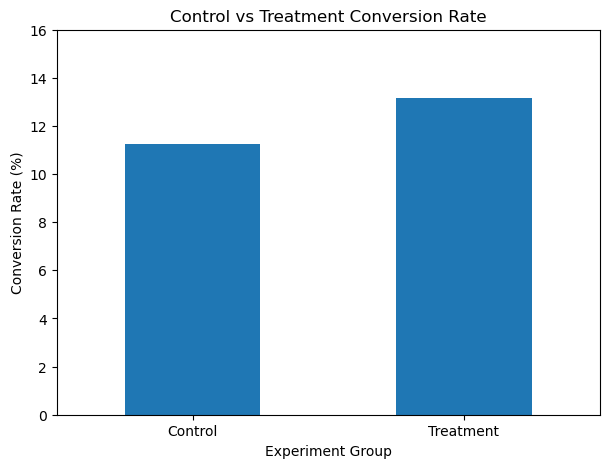

In [21]:
# Visualization and Final Interpretation

# Calculate conversion rates using existing group_summary
conversion_rates = (
    group_summary["converted_users"] /
    group_summary["total_users"]
) * 100

# Create bar chart
conversion_rates.plot(kind="bar", figsize=(7, 5))

plt.title("Control vs Treatment Conversion Rate")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 16)

plt.show()

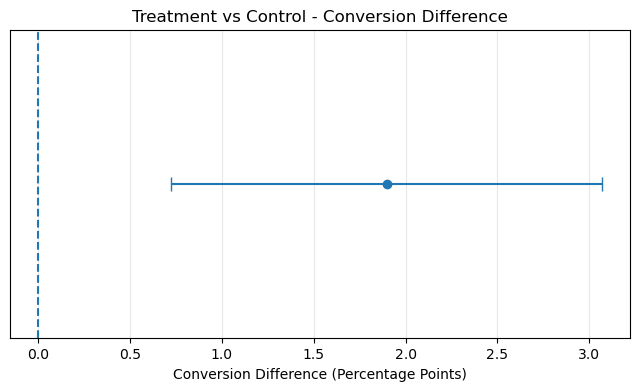

In [22]:
# Calculate conversion difference
difference = (
    conversion_rates.loc["Treatment"] -
    conversion_rates.loc["Control"]
)

# Calculate error distances
lower_error = difference - ci_low
upper_error = ci_high - difference

# Plot confidence interval
plt.figure(figsize=(8, 4))

plt.errorbar(
    difference, 0,
    xerr=[[lower_error], [upper_error]],
    fmt="o",
    capsize=5
)

plt.axvline(0, linestyle="--")
plt.title("Treatment vs Control - Conversion Difference")
plt.xlabel("Conversion Difference (Percentage Points)")
plt.yticks([])
plt.grid(axis="x", alpha=0.3)

plt.show()

In [23]:
# Create final statistical findings table
statistical_findings = pd.DataFrame({
    "Metric": [
        "Control Conversion Rate (%)",
        "Treatment Conversion Rate (%)",
        "Conversion Difference (pp)",
        "Relative Lift (%)",
        "Z-Statistic",
        "P-Value",
        "95% CI Lower Bound (pp)",
        "95% CI Upper Bound (pp)",
        "SRM P-Value"
    ],

    "Value": [
        conversion_rates.loc["Control"],
        conversion_rates.loc["Treatment"],
        difference,
        (difference / conversion_rates.loc["Control"]) * 100,
        z_stat,
        p_value,
        ci_low,
        ci_high,
        srm_p_value
    ]
})

print(statistical_findings.round(4))

                          Metric    Value
0    Control Conversion Rate (%)  11.2669
1  Treatment Conversion Rate (%)  13.1636
2     Conversion Difference (pp)   1.8967
3              Relative Lift (%)  16.8342
4                    Z-Statistic   3.1723
5                        P-Value   0.0015
6        95% CI Lower Bound (pp)   0.7255
7        95% CI Upper Bound (pp)   3.0679
8                    SRM P-Value   0.8695


In [24]:
# Create combined experiment summary

final_summary = pd.DataFrame([{
    "Control_CVR": conversion_rates.loc["Control"],
    "Treatment_CVR": conversion_rates.loc["Treatment"],
    "Absolute_Lift_pp": difference,
    "Relative_Lift_pct": (difference / conversion_rates.loc["Control"]) * 100,
    "Z_Statistic": z_stat,
    "P_Value": p_value,
    "CI_Lower_pp": ci_low,
    "CI_Upper_pp": ci_high,
    "SRM_P_Value": srm_p_value,

    "Unique_User_IDs": df["user_id"].nunique(),
    "Duplicate_Users": df["user_id"].duplicated().sum(),
    "Missing_Outcomes": df["converted"].isnull().sum(),
    "Invalid_Variants": (~df["variant"].isin(["Control", "Treatment"])).sum(),
    "Invalid_Conversions": (
        df["converted"].notna() &
        ~df["converted"].isin([0, 1])
    ).sum(),

    "Statistical_Significance": "Passed" if p_value < 0.05 else "Not Passed",
    "Confidence_Interval_Check": "Passed" if ci_low > 0 else "Not Passed",
    "SRM_Check": "Passed" if srm_p_value >= 0.01 else "Not Passed",

    "Final_Decision": (
        "Promising Candidate for Rollout"
        if p_value < 0.05 and ci_low > 0 and srm_p_value >= 0.01
        else "Further Investigation Required"
    )
}])

print(final_summary.T)

                                                         0
Control_CVR                                        11.2669
Treatment_CVR                                    13.163588
Absolute_Lift_pp                                  1.896688
Relative_Lift_pct                                16.834156
Z_Statistic                                       3.172295
P_Value                                           0.001512
CI_Lower_pp                                       0.725451
CI_Upper_pp                                       3.067924
SRM_P_Value                                       0.869482
Unique_User_IDs                                      12000
Duplicate_Users                                          0
Missing_Outcomes                                         0
Invalid_Variants                                         0
Invalid_Conversions                                      0
Statistical_Significance                            Passed
Confidence_Interval_Check                           Pass

In [25]:
import os

output_path = os.path.join(
    os.path.dirname(file_path),
    "AB_Test_Final_Summary.csv"
)

final_summary.to_csv(output_path, index=False)

print("Final summary exported successfully!")

Final summary exported successfully!
